In [1]:
# ProThaali - Personalized Meal Recommendation System

print("Welcome to ProThaali!")
print("Our ML meal recommendation project is starting.")

Welcome to ProThaali!
Our ML meal recommendation project is starting.


In [2]:
# Import the libraries required for ProThaali

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
# ProThaali - Initial Meal Dataset

meals = [
    # PANEER MEALS
    {"meal_name": "Paneer Bhurji", "main_ingredient": "Paneer", "protein_g": 25, "calories": 350},
    {"meal_name": "Paneer Tikka", "main_ingredient": "Paneer", "protein_g": 28, "calories": 400},
    {"meal_name": "Paneer Wrap", "main_ingredient": "Paneer", "protein_g": 24, "calories": 450},
    {"meal_name": "Palak Paneer", "main_ingredient": "Paneer", "protein_g": 22, "calories": 380},
    {"meal_name": "Paneer Salad", "main_ingredient": "Paneer", "protein_g": 26, "calories": 320},
    {"meal_name": "Paneer Sandwich", "main_ingredient": "Paneer", "protein_g": 23, "calories": 420},
    {"meal_name": "Paneer Pulao", "main_ingredient": "Paneer", "protein_g": 20, "calories": 500},
    {"meal_name": "Paneer Oats Bowl", "main_ingredient": "Paneer", "protein_g": 27, "calories": 390},
    {"meal_name": "Paneer Curry", "main_ingredient": "Paneer", "protein_g": 24, "calories": 430},
    {"meal_name": "Paneer Stuffed Roti", "main_ingredient": "Paneer", "protein_g": 21, "calories": 460},
    {"meal_name": "Paneer Chilla", "main_ingredient": "Paneer", "protein_g": 25, "calories": 340},
    {"meal_name": "Paneer Rice Bowl", "main_ingredient": "Paneer", "protein_g": 26, "calories": 480},

    # TOFU MEALS
    {"meal_name": "Tofu Stir Fry", "main_ingredient": "Tofu", "protein_g": 20, "calories": 300},
    {"meal_name": "Tofu Salad", "main_ingredient": "Tofu", "protein_g": 18, "calories": 280},
    {"meal_name": "Tofu Wrap", "main_ingredient": "Tofu", "protein_g": 22, "calories": 420},
    {"meal_name": "Tofu Curry", "main_ingredient": "Tofu", "protein_g": 19, "calories": 350},
    {"meal_name": "Tofu Fried Rice", "main_ingredient": "Tofu", "protein_g": 21, "calories": 460},
    {"meal_name": "Tofu Bhurji", "main_ingredient": "Tofu", "protein_g": 23, "calories": 330},
    {"meal_name": "Tofu Sandwich", "main_ingredient": "Tofu", "protein_g": 20, "calories": 390},
    {"meal_name": "Tofu Buddha Bowl", "main_ingredient": "Tofu", "protein_g": 24, "calories": 440},
    {"meal_name": "Tofu Skewers", "main_ingredient": "Tofu", "protein_g": 22, "calories": 310},
    {"meal_name": "Tofu Noodles", "main_ingredient": "Tofu", "protein_g": 19, "calories": 470},
    {"meal_name": "Tofu Paratha", "main_ingredient": "Tofu", "protein_g": 21, "calories": 430},
    {"meal_name": "Tofu Lentil Bowl", "main_ingredient": "Tofu", "protein_g": 25, "calories": 410},

    # SOYA MEALS
    {"meal_name": "Soya Chunks Curry", "main_ingredient": "Soya", "protein_g": 32, "calories": 380},
    {"meal_name": "Soya Pulao", "main_ingredient": "Soya", "protein_g": 28, "calories": 450},
    {"meal_name": "Soya Keema", "main_ingredient": "Soya", "protein_g": 35, "calories": 400},
    {"meal_name": "Soya Salad", "main_ingredient": "Soya", "protein_g": 30, "calories": 320},
    {"meal_name": "Soya Wrap", "main_ingredient": "Soya", "protein_g": 29, "calories": 430},
    {"meal_name": "Soya Fried Rice", "main_ingredient": "Soya", "protein_g": 31, "calories": 480},
    {"meal_name": "Soya Cutlet", "main_ingredient": "Soya", "protein_g": 27, "calories": 350},
    {"meal_name": "Soya Bhurji", "main_ingredient": "Soya", "protein_g": 33, "calories": 370},
    {"meal_name": "Soya Sandwich", "main_ingredient": "Soya", "protein_g": 26, "calories": 410},
    {"meal_name": "Soya Rice Bowl", "main_ingredient": "Soya", "protein_g": 34, "calories": 460},
    {"meal_name": "Soya Stuffed Roti", "main_ingredient": "Soya", "protein_g": 28, "calories": 440},
    {"meal_name": "Soya Vegetable Bowl", "main_ingredient": "Soya", "protein_g": 30, "calories": 390},

    # EGG MEALS
    {"meal_name": "Egg Bhurji", "main_ingredient": "Eggs", "protein_g": 18, "calories": 280},
    {"meal_name": "Boiled Egg Salad", "main_ingredient": "Eggs", "protein_g": 20, "calories": 300},
    {"meal_name": "Egg Omelette", "main_ingredient": "Eggs", "protein_g": 17, "calories": 250},
    {"meal_name": "Egg Sandwich", "main_ingredient": "Eggs", "protein_g": 21, "calories": 390},
    {"meal_name": "Egg Curry", "main_ingredient": "Eggs", "protein_g": 19, "calories": 360},
    {"meal_name": "Egg Fried Rice", "main_ingredient": "Eggs", "protein_g": 16, "calories": 450},
    {"meal_name": "Egg Wrap", "main_ingredient": "Eggs", "protein_g": 22, "calories": 420},
    {"meal_name": "Egg Toast", "main_ingredient": "Eggs", "protein_g": 18, "calories": 320},
    {"meal_name": "Egg Protein Bowl", "main_ingredient": "Eggs", "protein_g": 24, "calories": 400},
    {"meal_name": "Egg Chilla", "main_ingredient": "Eggs", "protein_g": 20, "calories": 340},
    {"meal_name": "Egg Rice Bowl", "main_ingredient": "Eggs", "protein_g": 19, "calories": 430},
    {"meal_name": "Egg Veggie Scramble", "main_ingredient": "Eggs", "protein_g": 21, "calories": 310},
]

# Convert the list into a Pandas DataFrame
df = pd.DataFrame(meals)

print("Dataset created successfully!")
print("Total meals:", len(df))

# Display the first 5 rows
df.head()

Dataset created successfully!
Total meals: 48


,meal_name,main_ingredient,protein_g,calories
0,Paneer Bhurji,Paneer,25,350
1,Paneer Tikka,Paneer,28,400
2,Paneer Wrap,Paneer,24,450
3,Palak Paneer,Paneer,22,380
4,Paneer Salad,Paneer,26,320


In [4]:
# ProThaali - Dataset Inspection

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nMeals per ingredient:")
print(df["main_ingredient"].value_counts())

print("\nNutrition statistics:")
print(df[["protein_g", "calories"]].describe())

Dataset shape: (48, 4)

Column names:
['meal_name', 'main_ingredient', 'protein_g', 'calories']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   meal_name        48 non-null     object
 1   main_ingredient  48 non-null     object
 2   protein_g        48 non-null     int64 
 3   calories         48 non-null     int64 
dtypes: int64(2), object(2)
memory usage: 1.6+ KB

Missing values:
meal_name          0
main_ingredient    0
protein_g          0
calories           0
dtype: int64

Duplicate rows:
0

Meals per ingredient:
main_ingredient
Paneer    12
Tofu      12
Soya      12
Eggs      12
Name: count, dtype: int64

Nutrition statistics:
       protein_g    calories
count  48.000000   48.000000
mean   23.812500  388.333333
std     4.738508   61.482858
min    16.000000  250.000000
25%    20.000000  340.000000
50%    23.000

In [5]:
# ProThaali - Data Validation

# Check whether protein and calories are positive
print("Protein values valid:", (df["protein_g"] > 0).all())
print("Calories values valid:", (df["calories"] > 0).all())

# Check allowed ingredient categories
allowed_ingredients = ["Paneer", "Tofu", "Soya", "Eggs"]

print(
    "Ingredient categories valid:",
    df["main_ingredient"].isin(allowed_ingredients).all()
)

# Remove duplicate rows if any
df = df.drop_duplicates()

# Reset index after cleaning
df = df.reset_index(drop=True)

print("\nDataset cleaned successfully!")
print("Final dataset size:", df.shape)

Protein values valid: True
Calories values valid: True
Ingredient categories valid: True

Dataset cleaned successfully!
Final dataset size: (48, 4)


In [6]:
# Save the ProThaali dataset

df.to_csv("prothaali_meals.csv", index=False)

print("Dataset saved successfully as prothaali_meals.csv")

Dataset saved successfully as prothaali_meals.csv


In [7]:
from google.colab import files

files.download("prothaali_meals.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

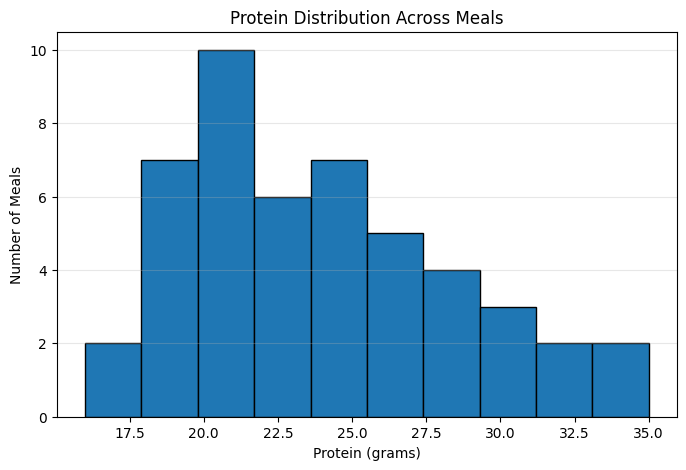

In [8]:
# Protein distribution across meals

plt.figure(figsize=(8, 5))

plt.hist(df["protein_g"], bins=10, edgecolor="black")

plt.title("Protein Distribution Across Meals")
plt.xlabel("Protein (grams)")
plt.ylabel("Number of Meals")

plt.grid(axis="y", alpha=0.3)

plt.show()

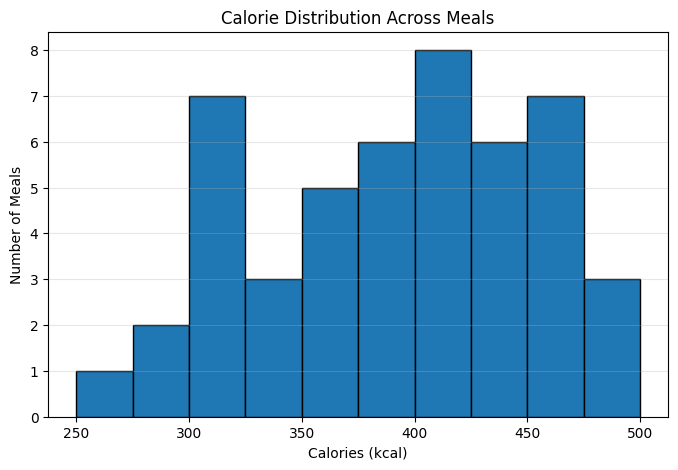

In [9]:
# Calorie distribution across meals

plt.figure(figsize=(8, 5))

plt.hist(df["calories"], bins=10, edgecolor="black")

plt.title("Calorie Distribution Across Meals")
plt.xlabel("Calories (kcal)")
plt.ylabel("Number of Meals")

plt.grid(axis="y", alpha=0.3)

plt.show()

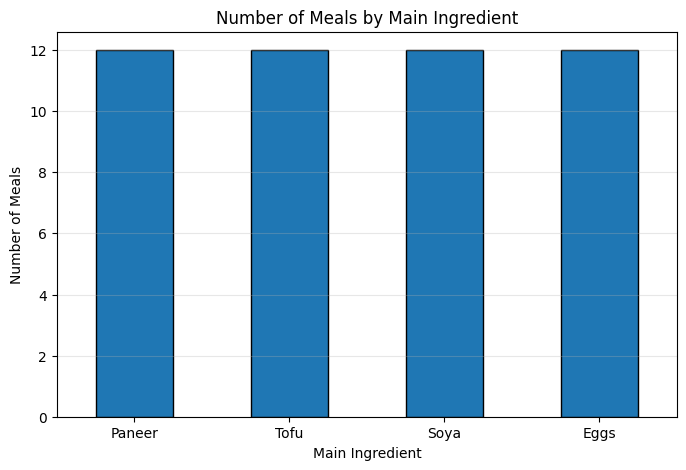

In [10]:
# Count meals by main ingredient

ingredient_counts = df["main_ingredient"].value_counts()

plt.figure(figsize=(8, 5))

ingredient_counts.plot(kind="bar", edgecolor="black")

plt.title("Number of Meals by Main Ingredient")
plt.xlabel("Main Ingredient")
plt.ylabel("Number of Meals")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [11]:
def calculate_meal_score(protein, calories, target_protein, target_calories):

    # Calculate differences from the user's targets
    protein_deviation = abs(protein - target_protein)
    calorie_deviation = abs(calories - target_calories)

    # Normalize deviations
    normalized_protein = protein_deviation / 5
    normalized_calories = calorie_deviation / 200

    # Calculate final score
    score = 100 - 50 * (
        0.6 * normalized_protein +
        0.4 * normalized_calories
    )

    # Keep score between 1 and 100
    score = max(1, min(100, score))

    return round(score, 2)


print("Scoring system created successfully!")

Scoring system created successfully!


In [12]:
test_score = calculate_meal_score(
    protein=25,
    calories=400,
    target_protein=25,
    target_calories=400
)

print("Test Score:", test_score)

Test Score: 100


In [13]:
test_score = calculate_meal_score(
    protein=15,
    calories=700,
    target_protein=25,
    target_calories=400
)

print("Test Score:", test_score)

Test Score: 10.0


In [14]:
# Set user nutrition targets
target_protein = 25
target_calories = 400

# Calculate score for every meal
df["score"] = df.apply(
    lambda row: calculate_meal_score(
        row["protein_g"],
        row["calories"],
        target_protein,
        target_calories
    ),
    axis=1
)

# Sort meals from highest score to lowest
ranked_meals = df.sort_values(
    by="score",
    ascending=False
)

# Display the top 5 meals
ranked_meals.head(5)

,meal_name,main_ingredient,protein_g,calories,score
23,Tofu Lentil Bowl,Tofu,25,410,99.0
0,Paneer Bhurji,Paneer,25,350,95.0
44,Egg Protein Bowl,Eggs,24,400,94.0
10,Paneer Chilla,Paneer,25,340,94.0
32,Soya Sandwich,Soya,26,410,93.0


In [15]:
# Choose your preferred ingredient
selected_ingredient = "Paneer"

# Filter meals by ingredient
filtered_df = df[df["main_ingredient"] == selected_ingredient]

# Rank filtered meals using nutrition targets
filtered_df = filtered_df.copy()

filtered_df["score"] = filtered_df.apply(
    lambda row: calculate_meal_score(
        row["protein_g"],
        row["calories"],
        target_protein,
        target_calories
    ),
    axis=1
)

# Sort by score
filtered_ranked_meals = filtered_df.sort_values(
    by="score",
    ascending=False
)

# Display top 5 recommendations
filtered_ranked_meals.head(5)

,meal_name,main_ingredient,protein_g,calories,score
0,Paneer Bhurji,Paneer,25,350,95.0
10,Paneer Chilla,Paneer,25,340,94.0
8,Paneer Curry,Paneer,24,430,91.0
2,Paneer Wrap,Paneer,24,450,89.0
7,Paneer Oats Bowl,Paneer,27,390,87.0


In [16]:
# Choose your preferred ingredient
selected_ingredient = "Tofu"

# Filter meals by ingredient
filtered_df = df[df["main_ingredient"] == selected_ingredient]

# Rank filtered meals using nutrition targets
filtered_df = filtered_df.copy()

filtered_df["score"] = filtered_df.apply(
    lambda row: calculate_meal_score(
        row["protein_g"],
        row["calories"],
        target_protein,
        target_calories
    ),
    axis=1
)

# Sort by score
filtered_ranked_meals = filtered_df.sort_values(
    by="score",
    ascending=False
)

# Display top 5 recommendations
filtered_ranked_meals.head(5)

,meal_name,main_ingredient,protein_g,calories,score
23,Tofu Lentil Bowl,Tofu,25,410,99.0
19,Tofu Buddha Bowl,Tofu,24,440,90.0
17,Tofu Bhurji,Tofu,23,330,81.0
14,Tofu Wrap,Tofu,22,420,80.0
22,Tofu Paratha,Tofu,21,430,73.0


In [17]:
# Generate synthetic training data
np.random.seed(42)

num_samples = 1000

protein_deviation = np.random.uniform(0, 20, num_samples)
calorie_deviation = np.random.uniform(0, 800, num_samples)

# Normalize deviations
protein_normalized = protein_deviation / 5
calorie_normalized = calorie_deviation / 200

# Generate scores using our scoring formula
scores = 100 - 50 * (
    0.6 * protein_normalized +
    0.4 * calorie_normalized
)

# Keep scores between 1 and 100
scores = np.clip(scores, 1, 100)

# Create training dataset
training_data = pd.DataFrame({
    "protein_deviation_normalized": protein_normalized,
    "calorie_deviation_normalized": calorie_normalized,
    "score": scores
})

training_data.head()

,protein_deviation_normalized,calorie_deviation_normalized,score
0,1.498160,0.740532,40.244551
1,3.802857,2.167604,1.000000
2,2.927976,3.491783,1.000000
3,2.394634,2.928900,1.000000
4,0.624075,3.226245,16.752871


In [22]:
# Select input features (X)
X = training_data[
    [
        "protein_deviation_normalized",
        "calorie_deviation_normalized"
    ]
]

# Select target (y)
y = training_data["score"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Model training completed successfully!
Training samples: 800
Testing samples: 200


In [23]:
# Make predictions on test data
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION RESULTS")
print("-----------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MODEL EVALUATION RESULTS
-----------------------
MAE: 0.0
RMSE: 0.0
R2 Score: 1.0


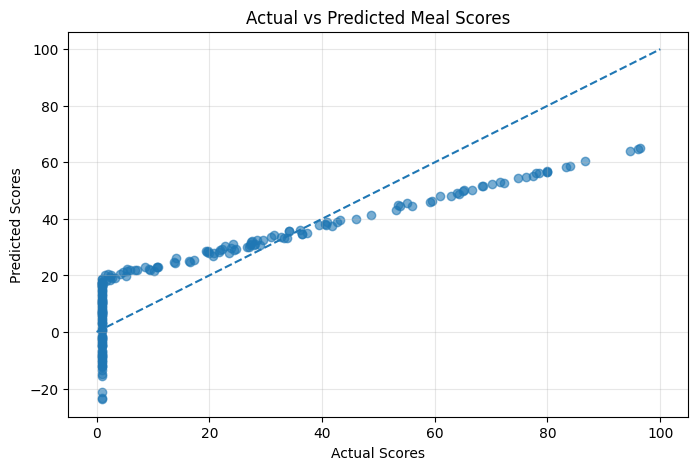

In [20]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [0, 100],
    [0, 100],
    linestyle="--"
)

plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted Meal Scores")

plt.grid(alpha=0.3)
plt.show()

In [21]:
# Generate improved synthetic training data
np.random.seed(42)

num_samples = 1000

protein_deviation = np.random.uniform(0, 5, num_samples)
calorie_deviation = np.random.uniform(0, 200, num_samples)

protein_normalized = protein_deviation / 5
calorie_normalized = calorie_deviation / 200

scores = 100 - 50 * (
    0.6 * protein_normalized +
    0.4 * calorie_normalized
)

training_data = pd.DataFrame({
    "protein_deviation_normalized": protein_normalized,
    "calorie_deviation_normalized": calorie_normalized,
    "score": scores
})

training_data.head()

,protein_deviation_normalized,calorie_deviation_normalized,score
0,0.374540,0.185133,85.061138
1,0.950714,0.541901,60.640552
2,0.731994,0.872946,60.581265
3,0.598658,0.732225,67.395748
4,0.156019,0.806561,79.188218


In [24]:
# Set user preferences
target_protein = 25
target_calories = 400
selected_ingredient = "Paneer"

# Filter meals by ingredient
recommendation_df = df[
    df["main_ingredient"] == selected_ingredient
].copy()

# Calculate normalized deviations
recommendation_df["protein_deviation_normalized"] = (
    abs(recommendation_df["protein_g"] - target_protein) / 5
)

recommendation_df["calorie_deviation_normalized"] = (
    abs(recommendation_df["calories"] - target_calories) / 200
)

# Prepare features for ML model
X_recommendation = recommendation_df[
    [
        "protein_deviation_normalized",
        "calorie_deviation_normalized"
    ]
]

# Predict scores using trained model
recommendation_df["score"] = model.predict(X_recommendation)

# Keep scores between 1 and 100
recommendation_df["score"] = recommendation_df["score"].clip(1, 100)

# Sort by highest score
recommendation_df = recommendation_df.sort_values(
    by="score",
    ascending=False
)

# Display top 5 meals
recommendation_df[
    ["meal_name", "main_ingredient", "protein_g", "calories", "score"]
].head(5)

,meal_name,main_ingredient,protein_g,calories,score
0,Paneer Bhurji,Paneer,25,350,95.0
10,Paneer Chilla,Paneer,25,340,94.0
8,Paneer Curry,Paneer,24,430,91.0
2,Paneer Wrap,Paneer,24,450,89.0
7,Paneer Oats Bowl,Paneer,27,390,87.0


In [25]:
# Set user preferences
target_protein = 25
target_calories = 400
selected_ingredient = "Soya"

# Filter meals by ingredient
recommendation_df = df[
    df["main_ingredient"] == selected_ingredient
].copy()

# Calculate normalized deviations
recommendation_df["protein_deviation_normalized"] = (
    abs(recommendation_df["protein_g"] - target_protein) / 5
)

recommendation_df["calorie_deviation_normalized"] = (
    abs(recommendation_df["calories"] - target_calories) / 200
)

# Prepare features for ML model
X_recommendation = recommendation_df[
    [
        "protein_deviation_normalized",
        "calorie_deviation_normalized"
    ]
]

# Predict scores using trained model
recommendation_df["score"] = model.predict(X_recommendation)

# Keep scores between 1 and 100
recommendation_df["score"] = recommendation_df["score"].clip(1, 100)

# Sort by highest score
recommendation_df = recommendation_df.sort_values(
    by="score",
    ascending=False
)

# Display top 5 meals
recommendation_df[
    ["meal_name", "main_ingredient", "protein_g", "calories", "score"]
].head(5)

,meal_name,main_ingredient,protein_g,calories,score
32,Soya Sandwich,Soya,26,410,93.0
30,Soya Cutlet,Soya,27,350,83.0
34,Soya Stuffed Roti,Soya,28,440,78.0
25,Soya Pulao,Soya,28,450,77.0
28,Soya Wrap,Soya,29,430,73.0


In [26]:
from google.colab import files
uploaded = files.upload()

Saving prothaali_300_meals_with_recipes (1).csv to prothaali_300_meals_with_recipes (1).csv


In [29]:
df = pd.read_csv("prothaali_300_meals_with_recipes (1).csv")

print("Total meals:", len(df))
print(df["main_ingredient"].value_counts())

Total meals: 300
main_ingredient
Paneer    75
Tofu      75
Soya      75
Eggs      75
Name: count, dtype: int64


In [30]:
print("Dataset shape:", df.shape)

print("\nMeals per ingredient:")
print(df["main_ingredient"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate meal names:")
print(df["meal_name"].duplicated().sum())

print("\nDataset columns:")
print(df.columns.tolist())

Dataset shape: (300, 6)

Meals per ingredient:
main_ingredient
Paneer    75
Tofu      75
Soya      75
Eggs      75
Name: count, dtype: int64

Missing values:
meal_name            0
main_ingredient      0
protein_g            0
calories             0
ingredients          0
preparation_steps    0
dtype: int64

Duplicate meal names:
0

Dataset columns:
['meal_name', 'main_ingredient', 'protein_g', 'calories', 'ingredients', 'preparation_steps']


In [31]:
# Save validated dataset
df.to_csv("prothaali_300_meals.csv", index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [32]:
from google.colab import files
files.download("prothaali_300_meals.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
# Set nutrition targets and ingredient preference
target_protein = 25
target_calories = 400
selected_ingredient = "Paneer"

# Filter dataset
recommendation_df = df[
    df["main_ingredient"] == selected_ingredient
].copy()

# Calculate normalized deviations
recommendation_df["protein_deviation_normalized"] = (
    abs(recommendation_df["protein_g"] - target_protein) / 5
)

recommendation_df["calorie_deviation_normalized"] = (
    abs(recommendation_df["calories"] - target_calories) / 200
)

# Prepare ML inputs
X_recommendation = recommendation_df[
    [
        "protein_deviation_normalized",
        "calorie_deviation_normalized"
    ]
]

# Predict suitability scores
recommendation_df["score"] = model.predict(X_recommendation)

# Limit scores between 1 and 100
recommendation_df["score"] = recommendation_df["score"].clip(1, 100)

# Rank meals
recommendation_df = recommendation_df.sort_values(
    by="score",
    ascending=False
)

# Display top 5 meals
top_5 = recommendation_df.head(5)

print("TOP 5 PROTHAALI RECOMMENDATIONS")
print("=" * 40)

for _, meal in top_5.iterrows():
    print("\nMeal:", meal["meal_name"])
    print("Protein:", meal["protein_g"], "g")
    print("Calories:", meal["calories"], "kcal")
    print("Score:", round(meal["score"], 2), "/100")
    print("Ingredients:", meal["ingredients"])
    print("Preparation:", meal["preparation_steps"])
    print("-" * 60)

TOP 5 PROTHAALI RECOMMENDATIONS

Meal: Mushroom Paneer Sandwich
Protein: 25 g
Calories: 387 kcal
Score: 98.7 /100
Ingredients: paneer; mushrooms, garlic, onion, and mixed herbs; salt, cooking oil, and spices; whole-wheat roti or bread, as appropriate
Preparation: 1. Wash and cut or crumble the paneer, as needed. 2. Add mushrooms, garlic, onion, and mixed herbs and sauté with a little oil and spices. 3. Prepare a paneer filling and toast it between bread slices. 4. Adjust seasoning and serve warm.
------------------------------------------------------------

Meal: Classic Paneer Skewers
Protein: 25 g
Calories: 378 kcal
Score: 97.8 /100
Ingredients: paneer; onion, tomato, coriander, cumin, and turmeric; salt, cooking oil, and spices
Preparation: 1. Wash and cut or crumble the paneer, as needed. 2. Add onion, tomato, coriander, cumin, and turmeric and sauté with a little oil and spices. 3. Thread marinated paneer and vegetables onto skewers and grill. 4. Adjust seasoning and serve warm.
-

In [34]:
# Set nutrition targets and ingredient preference
target_protein = 25
target_calories = 400
selected_ingredient = "Tofu"

# Filter dataset
recommendation_df = df[
    df["main_ingredient"] == selected_ingredient
].copy()

# Calculate normalized deviations
recommendation_df["protein_deviation_normalized"] = (
    abs(recommendation_df["protein_g"] - target_protein) / 5
)

recommendation_df["calorie_deviation_normalized"] = (
    abs(recommendation_df["calories"] - target_calories) / 200
)

# Prepare ML inputs
X_recommendation = recommendation_df[
    [
        "protein_deviation_normalized",
        "calorie_deviation_normalized"
    ]
]

# Predict suitability scores
recommendation_df["score"] = model.predict(X_recommendation)

# Limit scores between 1 and 100
recommendation_df["score"] = recommendation_df["score"].clip(1, 100)

# Rank meals
recommendation_df = recommendation_df.sort_values(
    by="score",
    ascending=False
)

# Display top 5 meals
top_5 = recommendation_df.head(5)

print("TOP 5 PROTHAALI RECOMMENDATIONS")
print("=" * 40)

for _, meal in top_5.iterrows():
    print("\nMeal:", meal["meal_name"])
    print("Protein:", meal["protein_g"], "g")
    print("Calories:", meal["calories"], "kcal")
    print("Score:", round(meal["score"], 2), "/100")
    print("Ingredients:", meal["ingredients"])
    print("Preparation:", meal["preparation_steps"])
    print("-" * 60)

TOP 5 PROTHAALI RECOMMENDATIONS

Meal: Spinach Tofu Rice Bowl
Protein: 25 g
Calories: 403 kcal
Score: 99.7 /100
Ingredients: tofu; spinach, garlic, onion, and black pepper; salt, cooking oil, and spices; rice
Preparation: 1. Drain the tofu and cut or crumble it, as needed. 2. Add spinach, garlic, onion, and black pepper and sauté with a little oil and spices. 3. Serve cooked tofu and vegetables over rice. 4. Adjust seasoning and serve warm.
------------------------------------------------------------

Meal: Capsicum Tofu Rice Bowl
Protein: 24 g
Calories: 403 kcal
Score: 93.7 /100
Ingredients: tofu; capsicum, onion, tomato, and paprika; salt, cooking oil, and spices; rice
Preparation: 1. Drain the tofu and cut or crumble it, as needed. 2. Add capsicum, onion, tomato, and paprika and sauté with a little oil and spices. 3. Serve cooked tofu and vegetables over rice. 4. Adjust seasoning and serve warm.
------------------------------------------------------------

Meal: Spinach Tofu Chilla


In [35]:
# Final dataset summary

print("PROTHAALI DATASET SUMMARY")
print("=" * 40)

print("Total meals:", len(df))
print("Unique meals:", df["meal_name"].nunique())
print("Categories:", df["main_ingredient"].nunique())

print("\nCategory distribution:")
print(df["main_ingredient"].value_counts())

print("\nAverage protein by ingredient:")
print(df.groupby("main_ingredient")["protein_g"].mean().round(2))

print("\nAverage calories by ingredient:")
print(df.groupby("main_ingredient")["calories"].mean().round(2))

print("\nOverall nutrition statistics:")
print(df[["protein_g", "calories"]].describe().round(2))

PROTHAALI DATASET SUMMARY
Total meals: 300
Unique meals: 300
Categories: 4

Category distribution:
main_ingredient
Paneer    75
Tofu      75
Soya      75
Eggs      75
Name: count, dtype: int64

Average protein by ingredient:
main_ingredient
Eggs      19.25
Paneer    24.07
Soya      29.28
Tofu      20.69
Name: protein_g, dtype: float64

Average calories by ingredient:
main_ingredient
Eggs      373.56
Paneer    410.99
Soya      406.52
Tofu      373.45
Name: calories, dtype: float64

Overall nutrition statistics:
       protein_g  calories
count     300.00    300.00
mean       23.32    391.13
std         4.55     61.83
min        15.00    253.00
25%        20.00    340.00
50%        22.00    389.00
75%        27.00    445.50
max        36.00    522.00


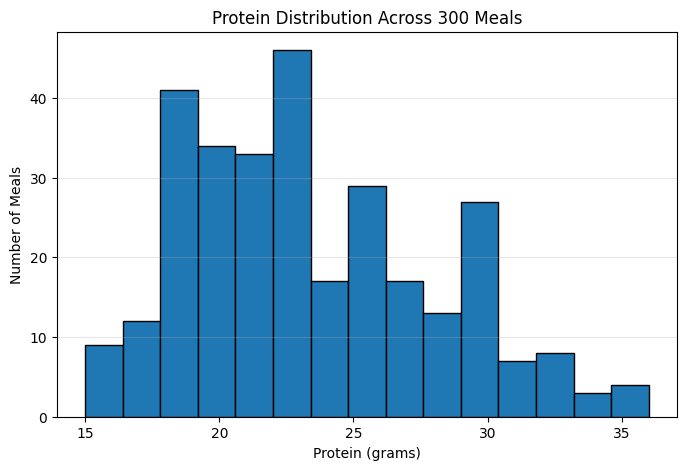

In [36]:
plt.figure(figsize=(8, 5))

plt.hist(df["protein_g"], bins=15, edgecolor="black")

plt.title("Protein Distribution Across 300 Meals")
plt.xlabel("Protein (grams)")
plt.ylabel("Number of Meals")

plt.grid(axis="y", alpha=0.3)
plt.show()

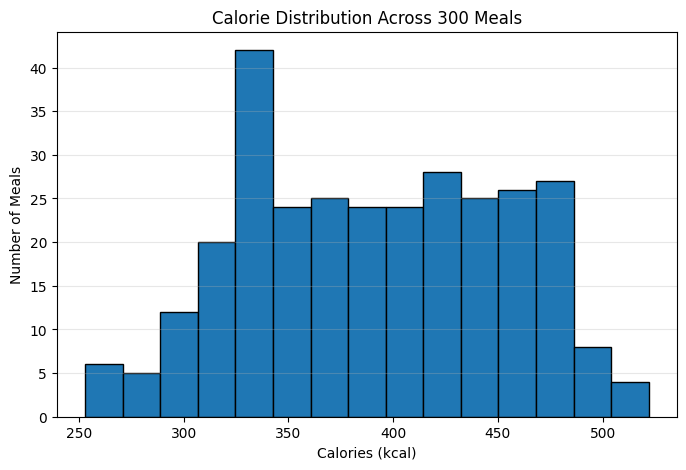

In [37]:
plt.figure(figsize=(8, 5))

plt.hist(df["calories"], bins=15, edgecolor="black")

plt.title("Calorie Distribution Across 300 Meals")
plt.xlabel("Calories (kcal)")
plt.ylabel("Number of Meals")

plt.grid(axis="y", alpha=0.3)
plt.show()

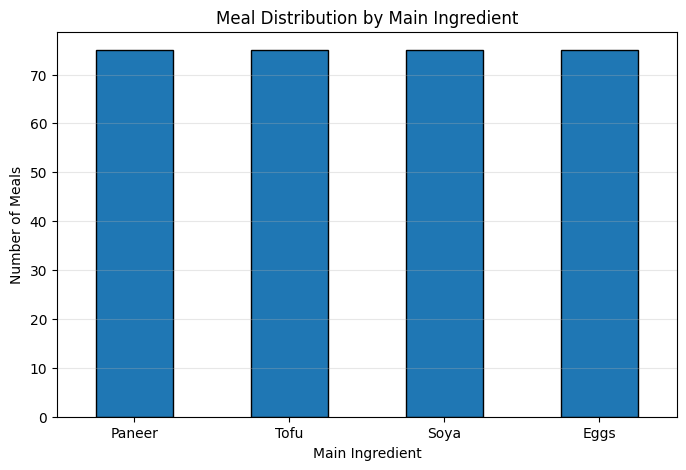

In [38]:
ingredient_counts = df["main_ingredient"].value_counts()

plt.figure(figsize=(8, 5))

ingredient_counts.plot(kind="bar", edgecolor="black")

plt.title("Meal Distribution by Main Ingredient")
plt.xlabel("Main Ingredient")
plt.ylabel("Number of Meals")

plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

In [39]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 105.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 132.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [40]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression

st.set_page_config(
    page_title="ProThaali",
    page_icon="🥗",
    layout="wide"
)

st.title("🥗 ProThaali")
st.subheader("Your Personalized Vegetarian Meal Recommendation System")

st.write(
    "Find meals based on your protein goals, calorie targets, "
    "and preferred main ingredient."
)

# Load dataset
df = pd.read_csv("prothaali_300_meals.csv")

# Train the ML model
np.random.seed(42)

num_samples = 1000

protein_deviation = np.random.uniform(0, 5, num_samples)
calorie_deviation = np.random.uniform(0, 200, num_samples)

protein_normalized = protein_deviation / 5
calorie_normalized = calorie_deviation / 200

scores = 100 - 50 * (
    0.6 * protein_normalized +
    0.4 * calorie_normalized
)

training_data = pd.DataFrame({
    "protein_deviation_normalized": protein_normalized,
    "calorie_deviation_normalized": calorie_normalized,
    "score": scores
})

X = training_data[
    ["protein_deviation_normalized",
     "calorie_deviation_normalized"]
]

y = training_data["score"]

model = LinearRegression()
model.fit(X, y)

# User inputs
st.sidebar.header("Your Nutrition Goals")

target_protein = st.sidebar.slider(
    "Target Protein (g)",
    min_value=1,
    max_value=40,
    value=25
)

target_calories = st.sidebar.slider(
    "Target Calories (kcal)",
    min_value=100,
    max_value=1000,
    value=400,
    step=50
)

selected_ingredient = st.sidebar.selectbox(
    "Choose Main Ingredient",
    ["Paneer", "Tofu", "Soya", "Eggs"]
)

st.markdown("---")

# Filter meals
recommendation_df = df[
    df["main_ingredient"] == selected_ingredient
].copy()

# Calculate deviations
recommendation_df["protein_deviation_normalized"] = (
    abs(recommendation_df["protein_g"] - target_protein) / 5
)

recommendation_df["calorie_deviation_normalized"] = (
    abs(recommendation_df["calories"] - target_calories) / 200
)

# Predict scores
X_recommendation = recommendation_df[
    ["protein_deviation_normalized",
     "calorie_deviation_normalized"]
]

recommendation_df["score"] = model.predict(X_recommendation)

recommendation_df["score"] = recommendation_df["score"].clip(1, 100)

# Sort recommendations
recommendation_df = recommendation_df.sort_values(
    "score",
    ascending=False
)

top_5 = recommendation_df.head(5)

# Display results
st.header("🏆 Your Top 5 Recommended Meals")

for index, meal in top_5.iterrows():

    score = meal["score"]

    if score >= 90:
        category = "Excellent Match"
    elif score >= 80:
        category = "Good Match"
    elif score >= 70:
        category = "Decent Match"
    else:
        category = "Less Suitable"

    with st.expander(
        f"{meal['meal_name']} | Score: {score:.2f}/100 | {category}",
        expanded=True
    ):

        col1, col2, col3 = st.columns(3)

        with col1:
            st.metric("Protein", f"{meal['protein_g']} g")

        with col2:
            st.metric("Calories", f"{meal['calories']} kcal")

        with col3:
            st.metric("Match Score", f"{score:.2f}/100")

        st.markdown("### 🧺 Ingredients")
        st.write(meal["ingredients"])

        st.markdown("### 👩‍🍳 Preparation Steps")
        st.write(meal["preparation_steps"])

# Chart
st.markdown("---")
st.header("📊 Recommendation Score Comparison")

chart_data = top_5.set_index("meal_name")["score"]

st.bar_chart(chart_data)

# Full results
st.markdown("---")
st.header("📋 All Matching Meals")

st.dataframe(
    recommendation_df[
        ["meal_name", "main_ingredient", "protein_g",
         "calories", "score"]
    ],
    use_container_width=True
)

st.caption(
    "Nutrition values are estimates. Recommendations are generated "
    "using a machine learning model trained on synthetic scoring data."
)

Writing app.py


In [41]:
from google.colab import files

files.download("app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
files.download("prothaali_300_meals.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>